In [75]:
from typing import TypedDict

class State(TypedDict):
    graph_state: str

In [76]:
def node_1(state):
    print("in node 1 function")

    return {"graph_state": state['graph_state'] +"I am"}
def node_2(state):
    print("in node 2 function")

    return {"graph_state": state['graph_state'] +" happy!"}

def node_3(state):
    print("in node 3 function")

    return {"graph state": state['graph_state']+"sad"}

In [77]:
import random
from typing import Literal

def decide_next_node(state) -> Literal["node_2", "node_3"]:
    user_input = state['graph_state'] 

    if random.random() < 0.5:
        return "node_2"
    else:
        return "node_3"


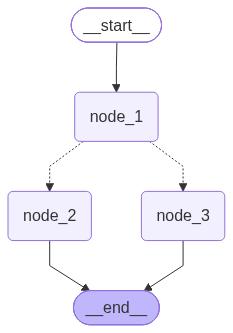

In [78]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

builder.add_edge(START, "node_1")
builder.add_conditional_edges("node_1", decide_next_node)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [79]:
graph.invoke({"graph_state" : "Hi, this is Lance."})

in node 1 function
in node 2 function


{'graph_state': 'Hi, this is Lance.I am happy!'}

In [80]:
import random
from typing import Literal

def decide_next_node_name(state) -> Literal["b", "c"]:

    if random.random() < 0.5:
        next_node = "b"
    else:
        next_node="c"

    return next_node

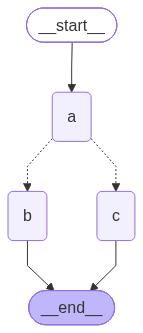

In [81]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

builder = StateGraph(State)
builder.add_node("a", node_1)
builder.add_node("b", node_2)
builder.add_node("c", node_3)

builder.add_edge(START, "a")
builder.add_conditional_edges("a", decide_next_node_name)
builder.add_edge("b", END)
builder.add_edge("c", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [82]:
graph.invoke({"graph_state": "Hello, I'm sai"})

in node 1 function
in node 3 function


{'graph_state': "Hello, I'm saiI am"}

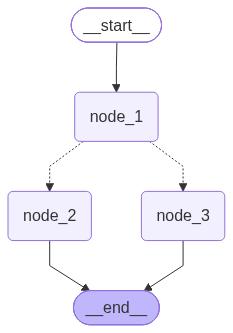

---Node 1---
---Node 3---


{'graph_state': 'Hi, this is Lance. I am sad!'}

In [83]:
from typing_extensions import TypedDict

class State(TypedDict):
    graph_state: str

def node_1(state):
    print("---Node 1---")
    return {"graph_state": state['graph_state'] +" I am"}

def node_2(state):
    print("---Node 2---")
    return {"graph_state": state['graph_state'] +" happy!"}

def node_3(state):
    print("---Node 3---")
    return {"graph_state": state['graph_state'] +" sad!"}


import random
from typing import Literal

def decide_mood(state) -> Literal["node_2", "node_3"]:
    
    # Often, we will use state to decide on the next node to visit
    user_input = state['graph_state'] 
    
    # Here, let's just do a 50 / 50 split between nodes 2, 3
    if random.random() < 0.5:

        # 50% of the time, we return Node 2
        return "node_2"
    
    # 50% of the time, we return Node 3
    return "node_3"

from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

# Build graph
builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

# Logic
builder.add_edge(START, "node_1")
builder.add_conditional_edges("node_1", decide_mood)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


graph.invoke({"graph_state" : "Hi, this is Lance."})